In [8]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Tabular data model using LightGBM 
In this notebook we take the next step after doing the feature engineering 

In [9]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

housing = fetch_california_housing(as_frame=True).frame
X = housing.drop(columns="MedHouseVal").copy()
y = housing["MedHouseVal"]

# Average number of bedrooms per room
X["BedroomRatio"] = (X["AveBedrms"] / X["AveRooms"].replace(0, np.nan))

# Average number of rooms available per resident
X["RoomsPerPerson"] = (X["AveRooms"] / X["AveOccup"].replace(0, np.nan))

# Reduce the skew in population values
X["LogPopulation"] = np.log1p(X["Population"])

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.006622 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2603
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 11
[LightGBM] [Info] Start training from score 2.071947
Training until validation scores don't improve for 10 rounds
[5]	training's rmse: 0.987648	training's l2: 0.975449	valid_1's rmse: 0.982639	valid_1's l2: 0.965579
[10]	training's rmse: 0.864588	training's l2: 0.747512	valid_1's rmse: 0.865468	valid_1's l2: 0.749035
[15]	training's rmse: 0.772156	training's l2: 0.596225	valid_1's rmse: 0.778689	valid_1's l2: 0.606357
[20]	training's rmse: 0.704696	training's l2: 0.496596	valid_1's rmse: 0.716618	valid_1's l2: 0.513542
[25]	training's rmse: 0.653195	training's l2: 0.426664	valid_1's rmse: 0.669247	valid_1's l2: 0.447892
[30]	training's rmse: 0.613087	training's l2: 0.375875	valid_1's rmse: 0.632055	val

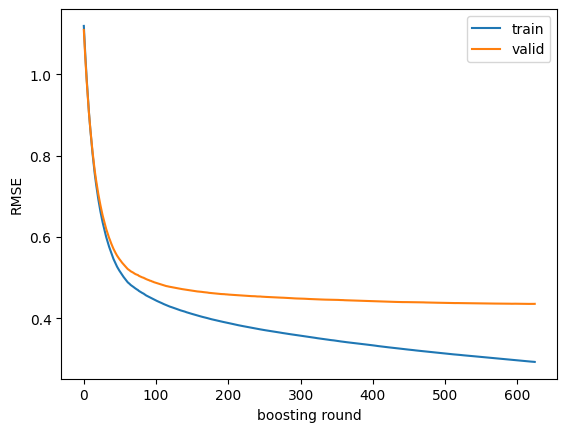

In [10]:
import lightgbm as lgb
import matplotlib.pyplot as plt

model = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.05)
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    eval_metric="rmse",
    callbacks=[lgb.early_stopping(10), lgb.log_evaluation(5)]
)

results = model.evals_result_
plt.plot(results["training"]["rmse"], label="train")
plt.plot(results["valid_1"]["rmse"], label="valid")
plt.xlabel("boosting round")
plt.ylabel("RMSE")
plt.legend()
plt.show()


## Questions:
* What does the parameter n_estimators value represent.
* What will be the effect of changing its value to 100 or 3000
* What does early stopping mean.
* What will be its effect on the validation loss if we change this value from 10 to 50
* Here by default rmse loss is used for training and l2 for validation. why?
* What could be some other losses useful in this context.
* Add some new features as done in the last lecture 2 notebook for this dataset.
* Observe the effect on training and validation loss

## Answers
* n_estimators represents the maximum number of decision trees in the LGBM decision path
* By changing to 100 trees, the model does not learn the patterns in the training data as deeply. That can be good for generalisation, but there is also a possibility of model underfitting due to the decision space not being split enough. The opposite is true changing it to 3000, the model learns patterns in the training data more deeply, but could end up being overfit.
* The model stops training once the validation score does not improve for a set number of iterations.
* The validation could improve, if the non-changing validation loss from earlier is a result of a local plateua that the model pushed through, but if not the validation loss could stay the same or worsen.
* RMSE might be being used because it preserves the errror in terms  closer to the original data, where as L2 is the same data, but with a root() function applied.
* MAE or L1 loss could be useful, as it is less prone to outliers, using absolute errors. Huber loss could also be used, which is also less sensitive to outliers, by blending quadratic loss at small error values with absolute loss at large ones.
*  Training L2 increased by 0.0001063, while validation L2 decreased by 0.001416 

# Optimizing the LGB parameters using Optuna


In [14]:
import optuna
from sklearn.metrics import mean_squared_error

def objective(trial):
    params = {
        "num_leaves": trial.suggest_int("num_leaves", 8, 256),
        "max_depth": trial.suggest_int("max_depth", 3, 9),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
   
    }
    model = lgb.LGBMRegressor(n_estimators=2000, **params)
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(5), lgb.log_evaluation(0)]
    )
    preds = model.predict(X_val)
    return mean_squared_error(y_val, preds) ** 0.5

study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=5)

print("Best params:", study.best_params)
print("Best RMSE:", study.best_value)


[I 2026-11-03 21:44:38,247] A new study created in memory with name: no-name-30b99276-55cb-49fa-a954-9c452ea5883f


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001139 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2603
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 11
[LightGBM] [Info] Start training from score 2.071947
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 5 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

[I 2026-11-03 21:44:38,736] Trial 0 finished with value: 0.4785600236710293 and parameters: {'num_leaves': 56, 'max_depth': 3, 'learning_rate': 0.07503276950364429, 'min_child_samples': 55, 'subsample': 0.7254335825097608, 'colsample_bytree': 0.816867167333459}. Best is trial 0 with value: 0.4785600236710293.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000987 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2603
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 11
[LightGBM] [Info] Start training from score 2.071947
Training until validation scores don't improve for 5 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

[I 2026-11-03 21:44:39,496] Trial 1 finished with value: 0.44589783718966597 and parameters: {'num_leaves': 92, 'max_depth': 8, 'learning_rate': 0.06255369143315047, 'min_child_samples': 25, 'subsample': 0.98349253413799, 'colsample_bytree': 0.8042217036464614}. Best is trial 1 with value: 0.44589783718966597.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Early stopping, best iteration is:
[220]	valid_0's l2: 0.198825
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000979 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2603
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 11
[LightGBM] [Info] Start training from score 2.0

... (2 outputs left out)

[I 2026-11-03 21:44:41,474] Trial 3 finished with value: 0.44743035292468203 and parameters: {'num_leaves': 55, 'max_depth': 9, 'learning_rate': 0.016324015671409366, 'min_child_samples': 15, 'subsample': 0.7424899185025395, 'colsample_bytree': 0.5426019237802081}. Best is trial 1 with value: 0.44589783718966597.


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001027 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2603
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 11
[LightGBM] [Info] Start training from score 2.071947
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
Training until validation scores don't improve for 5 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -in

[I 2026-11-03 21:44:41,955] Trial 4 finished with value: 0.45161921730984006 and parameters: {'num_leaves': 185, 'max_depth': 6, 'learning_rate': 0.08710255397801693, 'min_child_samples': 72, 'subsample': 0.5407572428097313, 'colsample_bytree': 0.742851150186669}. Best is trial 1 with value: 0.44589783718966597.


Best params: {'num_leaves': 92, 'max_depth': 8, 'learning_rate': 0.06255369143315047, 'min_child_samples': 25, 'subsample': 0.98349253413799, 'colsample_bytree': 0.8042217036464614}
Best RMSE: 0.44589783718966597


## Questions:
* What does it mean by the warning `[LightGBM] [Warning] No further splits with positive gain, best gain: -inf`
* Does it indicate changing the range of certain parameters.
* Whats the difference between `num_leaves` and `max_depth` and `n_estimators`
* What does parameters `subsample` and `colsample_bytree` control.
* What were the default parameters used for LGB in the cell above. 

## Answers
* The LGBM couldn't find another valid split to improve the training loss, possibly because of training constraints. -inf means that the eligible split wasn't found
* Yes, the range of some parameters should be changed to stop this from occuring. It could be becuase there are too many requested leaves for the amount of data available.
* num_leaves = the maximum number of leaves per tree, max_depth = the max number of splits allowed going along the path from the raw data to the leaves of a sequence of trees, n_estimators = The maximum number of trees that can be built during boosting
* subsample contols the amount of rows used in the training of the model, or the amount of samples from each feature used. colsample_bytree controls the amount of columns, ie features used in the training of the model.
* The only default parameter set explicitly is the number of estimators, n_estimators=2000. The remaining six parameters are set from a set of ranges, so that each trial has different values. The default param values for the function, as defined in the documentation, are: num_leaves=31,max_depth=-1,learning_rate=0.1,min_child_samples=20,subsample=1.0,colsample_bytree=1.0


In [15]:
default_model = lgb.LGBMRegressor(n_estimators=2000)
default_model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
                   callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
default_rmse = mean_squared_error(y_val, default_model.predict(X_val)) ** 0.5

tuned_model = lgb.LGBMRegressor(n_estimators=2000, **study.best_params)
tuned_model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
                callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])
tuned_rmse = mean_squared_error(y_val, tuned_model.predict(X_val)) ** 0.5

print("Default RMSE:", default_rmse)
print("Tuned RMSE:", tuned_rmse)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001026 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2603
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 11
[LightGBM] [Info] Start training from score 2.071947
Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[641]	valid_0's l2: 0.187961
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000985 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2603
[LightGBM] [Info] Number of data points in the train set: 16512, number of used features: 11
[LightGBM] [Info] Start training from score 2.071947
Training until validation scores don't improve for 50 rounds
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

## Questions:
* What do you learn from the tuning of LGB parameters 

## Answers
* I learned that the tuning of the LGB parameters can result in wildly different performance of the model. From the Undefitting-Overfitting tradeoff of estimator count, to the model continually raising errors when there is not enough data to populate the trees being created, there are many different factors to consider when tuning an LGB.
* The loss evaluation method also impacts the performance of the model, and so selecting the right loss function to compensate for the errors present in the specific usage is also important

# Takeaways:
Add a summary of reflections on this exersice

Tuning of model parameters is an important aspect of classifier design which is easy to overlook, and which can has a significant impact on performance.